# Solutions to the exercises of Chapter 8

Sample solutions for [Chapter 8, Internal flow and the Graetz problem](../../notebooks/part2_convection/08_internal_flow.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import convection_int, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import convection_int, properties, reference
from engtransport.plotting import use_style

use_style()

## Exercise 1. Water instead of oil

The velocity profile develops within about $0.05\,\mathrm{Re}\,D$ and the temperature profile
within $0.033\,\mathrm{Re}\,\mathrm{Pr}\,D$, Eq. (8.6).

In [2]:
Re, Pr = 1000.0, 3.0
print(f"hydrodynamic entry {0.05 * Re:.0f} D, thermal entry {0.033 * Re * Pr:.0f} D")
print(f"for the oil of Section 8.2: hydrodynamic {0.05 * 14.5:.1f} D, thermal {0.033 * 14.5 * 1194:.0f} D")

hydrodynamic entry 50 D, thermal entry 99 D
for the oil of Section 8.2: hydrodynamic 0.7 D, thermal 571 D


For water the two lengths are similar, 50 and 99 diameters: the velocity profile is still
developing over the first half of the thermal entry region. There the velocity near the
wall is larger than in the parabola, the thermal layer is thinner, and the heat transfer is
higher than the Graetz solution says. The Graetz result is therefore conservative for water:
a heater designed with it is slightly too long. For the oil, with $\mathrm{Pr} \approx 1200$,
the velocity develops within one diameter, and the Graetz assumption is excellent.

## Exercise 2. An electric heater

The heat needed is $\dot m c_p \Delta T_m$; with a uniform flux $q''$ the length is
$\dot m c_p \Delta T_m/(q''\pi D)$, and the bulk temperature rises linearly along it.

Re = 1592 (laminar), Pr = 6.97; length 4.99 m, zeta at the outlet 0.056
fully developed: wall 30.6 K above the bulk
at the outlet: bulk 45.0 C, wall 74.8 C (Nu = 4.47)


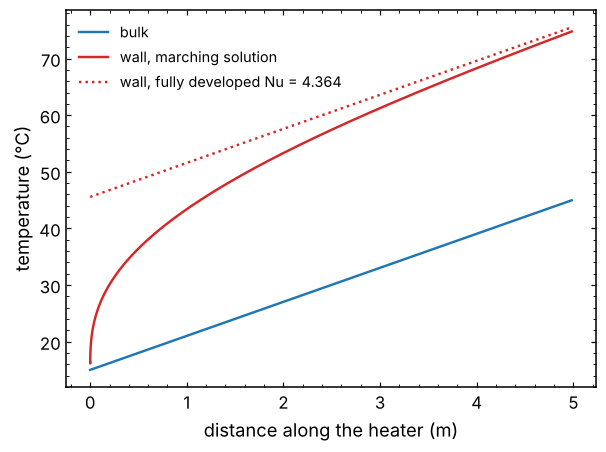

In [3]:
k, cp, mu, m_dot, D, q = 0.6, 4180.0, 1.0e-3, 0.01, 0.008, 1.0e4
Re = 4 * m_dot / (math.pi * D * mu)
Pr = mu * cp / k
L = m_dot * cp * 30.0 / (q * math.pi * D)
print(f"Re = {Re:.0f} (laminar), Pr = {Pr:.2f}; length {L:.2f} m, zeta at the outlet {L / D / (Re * Pr):.3f}")
print(f"fully developed: wall {q * D / (k * 48 / 11):.1f} K above the bulk")
march = reference.graetz_march(0.1, n_r=200, n_x=600, wall="flux")
zeta, Nu = march["zeta"][1:], march["Nu_x"][1:]
x = zeta * Re * Pr * D
T_m = 15.0 + q * math.pi * D * x / (m_dot * cp)
T_w = T_m + q * D / (k * Nu)
i_out = int(np.argmin(np.abs(x - L)))
print(f"at the outlet: bulk {T_m[i_out]:.1f} C, wall {T_w[i_out]:.1f} C (Nu = {Nu[i_out]:.2f})")

fig, ax = plt.subplots(figsize=(5.4, 4.0))
sel = x <= L
ax.plot(x[sel], T_m[sel], "C0", label="bulk")
ax.plot(x[sel], T_w[sel], "C3", label="wall, marching solution")
ax.plot(x[sel], T_m[sel] + q * D / (k * 48 / 11), "C3:", label="wall, fully developed Nu = 4.364")
ax.set_xlabel("distance along the heater (m)")
ax.set_ylabel("temperature (°C)")
ax.legend(loc="upper left")
plt.show()

**Figure S8.1.** Bulk and wall temperatures along the electric heater, with the local Nusselt
number from the marching solution and with the fully developed value.

The heater must be 5.0 m long. The bulk temperature rises linearly from 15 to 45 °C, and the
wall runs 31 K above it once the profile is developed, so the wall is hottest at the outlet,
at 75 °C. Near the inlet the thermal layer is thin and the wall is much closer to the bulk
temperature than the fully developed value suggests. With a uniform flux, the dangerous
place is the outlet, where the bulk is hottest; this is where scale forms first, and where
boiling would start if the flux were raised.

## Exercise 3. Pumping against heat transfer

In [4]:
water = properties.water_properties(273.15 + 110.0)
D_i = 0.1143 - 2 * 0.0036
rows = []
for U in (0.5, 1.0, 2.0):
    Re_w = water["rho"] * U * D_i / water["mu"]
    f = (0.790 * math.log(Re_w) - 1.64) ** -2
    dp = f * 1000.0 / D_i * water["rho"] * U**2 / 2
    power = dp * U * math.pi * D_i**2 / 4
    h = convection_int.nu_pipe_gnielinski(Re_w, water["Pr"]) * water["k"] / D_i
    rows.append((U, dp, power, h))
    print(f"U = {U:3.1f} m/s: pressure drop {dp / 1e3:6.1f} kPa/km, pumping power {power:6.0f} W/km, h = {h:6.0f} W/(m2 K)")
print(f"doubling 1 -> 2 m/s: pumping power x {rows[2][2] / rows[1][2]:.1f}, h x {rows[2][3] / rows[1][3]:.2f}")

U = 0.5 m/s: pressure drop   17.3 kPa/km, pumping power     78 W/km, h =   3251 W/(m2 K)
U = 1.0 m/s: pressure drop   60.7 kPa/km, pumping power    547 W/km, h =   5773 W/(m2 K)
U = 2.0 m/s: pressure drop  214.5 kPa/km, pumping power   3865 W/km, h =  10309 W/(m2 K)
doubling 1 -> 2 m/s: pumping power x 7.1, h x 1.79


Doubling the velocity multiplies the pumping power by 7 (it grows as $U^3$, softened by the
friction factor falling slightly) but raises $h$ by only 1.8. For the district-heating main
$h$ is irrelevant: the inside film is four thousand times less resistive than the
insulation (Section 8.3), so a higher $h$ changes nothing. What the operator chooses the
velocity for is the balance between the cost of pumping and the cost of larger pipes; the
heat loss depends on the insulation and the temperature, not on the flow inside. In a heat
exchanger, where the films are the main resistances, the same trade-off is real (Chapter 11).

## Exercise 4. A shear-thinning food

In [5]:
for n_pl in (1.0, 0.4):
    m = reference.graetz_march(2.0, n_r=200, n_x=800, n=n_pl, wall="flux")
    final = convection_int.nu_laminar_power_law_const_q(n_pl)
    z, Nu_x = m["zeta"][1:], m["Nu_x"][1:]
    j = np.where(Nu_x > 1.05 * final)[0][-1]
    print(f"n = {n_pl}: fully developed Nu = {final:.3f} (marching {Nu_x[-1]:.3f}); entry length zeta = {z[j]:.3f}")

n = 1.0: fully developed Nu = 4.364 (marching 4.364); entry length zeta = 0.043
n = 0.4: fully developed Nu = 4.907 (marching 4.907); entry length zeta = 0.040


The purée has a fully developed Nusselt number of 4.91, 12 % more than a Newtonian fluid,
because its blunter velocity profile moves more fluid near the wall. Its thermal entry
length, $\zeta \approx 0.040$, is a little shorter than the Newtonian 0.043. Since $\zeta$
contains $\mathrm{Re}\,\mathrm{Pr}$, which for a viscous food is large, the entry region may
still cover most of a real heater, as it did for the oil.